# Part B — Fine-tuning `bert-base-uncased` for Twitter NER

Transformers pre-trained on billions of words bring two things the BiLSTM lacks: **contextual representations**
(the same word gets a different vector in each sentence) and a **WordPiece sub-word vocabulary** that can represent
*any* string, so there are no out-of-vocabulary words. We fine-tune BERT with a token-classification head,
handle the word ↔ sub-token alignment explicitly, try several hyper-parameter settings and early stopping,
then join the sub-token predictions back into word-level entities.

In [1]:
import os, re, json, time, random, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
import tensorflow as tf
import transformers
from transformers import AutoConfig, AutoTokenizer, TFAutoModelForTokenClassification, create_optimizer
from transformers.utils import logging as hf_logging
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

hf_logging.set_verbosity_error()
tf.get_logger().setLevel("ERROR"); tf.autograph.set_verbosity(0)
pd.set_option("display.width", 160)

def show_wide(df, chunk=12):
    """Display a wide token table in chunks of columns so it stays readable."""
    for s in range(0, df.shape[1], chunk):
        display(df.iloc[:, s:s + chunk])
SEED = 42
tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")
PALETTE = ["#1D9BF0", "#0F1419", "#F91880", "#00BA7C", "#FFD400", "#7856FF", "#FF7A00", "#536471", "#8ECDF8", "#C1A3FF"]
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
SMOKE = os.environ.get("NER_SMOKE") == "1"          # tiny end-to-end dry run used to test the pipeline before the full run
DATA_DIR = "../data"
OUT_DIR = "../outputs/smoke" if SMOKE else "../outputs"
MODEL_DIR = f"{OUT_DIR}/bert_ner_smoke" if SMOKE else "../models/bert_ner"
os.makedirs(OUT_DIR, exist_ok=True)
print("TensorFlow", tf.__version__, "| transformers", transformers.__version__)

TensorFlow 2.15.0 | transformers 4.40.2


## 1. Data (same parsing and the same train / validation split as Part A)

In [2]:
def read_conll(path):
    sents, tags, toks, labs = [], [], [], []
    for line in open(path, encoding="utf-8"):
        line = line.rstrip("\r\n")
        if not line.strip():
            if toks: sents.append(toks); tags.append(labs); toks, labs = [], []
            continue
        parts = line.split("\t") if "\t" in line else line.split()
        toks.append(parts[0]); labs.append(parts[-1])
    if toks: sents.append(toks); tags.append(labs)
    return sents, tags

train_sents, train_tags = read_conll(f"{DATA_DIR}/wnut 16.txt.conll")
test_sents, test_tags = read_conll(f"{DATA_DIR}/wnut 16test.txt.conll")
has_ent = [int(any(t != "O" for t in ts)) for ts in train_tags]
tr_idx, va_idx = train_test_split(np.arange(len(train_sents)), test_size=0.10, random_state=SEED, stratify=has_ent)
X_tr, y_tr = [train_sents[i] for i in tr_idx], [train_tags[i] for i in tr_idx]
X_va, y_va = [train_sents[i] for i in va_idx], [train_tags[i] for i in va_idx]
X_te, y_te = test_sents, test_tags
if SMOKE:
    X_tr, y_tr, X_va, y_va, X_te, y_te = X_tr[:48], y_tr[:48], X_va[:24], y_va[:24], X_te[:40], y_te[:40]

ENTITY_TYPES = sorted({t[2:] for ts in train_tags for t in ts if t != "O"})
LABELS = ["O"] + [f"{p}-{e}" for e in ENTITY_TYPES for p in ("B", "I")]
label2id = {l: i for i, l in enumerate(LABELS)}; id2label = {i: l for l, i in label2id.items()}
print(f"train {len(X_tr)} | validation {len(X_va)} | test {len(X_te)} tweets | {len(LABELS)} labels")

train 2154 | validation 240 | test 3850 tweets | 21 labels


## 2. Loading the model configuration, tokenizer and model
`bert-base-uncased`: 12 layers, hidden size 768, 12 attention heads, 30,522-token WordPiece vocabulary (~110M parameters).
`TFAutoModelForTokenClassification` adds a dropout + linear layer on top of every token's final hidden state; we
pass our 21-label `id2label` / `label2id` mapping so the saved model is self-describing.

In [3]:
CHECKPOINT = "bert-base-uncased"
config = AutoConfig.from_pretrained(CHECKPOINT, num_labels=len(LABELS), id2label=id2label, label2id=label2id)
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)
print({k: getattr(config, k) for k in ["model_type", "num_hidden_layers", "hidden_size", "num_attention_heads",
                                        "vocab_size", "max_position_embeddings", "hidden_dropout_prob", "num_labels"]})
print("Tokenizer:", type(tokenizer).__name__, "| special tokens:", tokenizer.all_special_tokens)

{'model_type': 'bert', 'num_hidden_layers': 12, 'hidden_size': 768, 'num_attention_heads': 12, 'vocab_size': 30522, 'max_position_embeddings': 512, 'hidden_dropout_prob': 0.1, 'num_labels': 21}
Tokenizer: BertTokenizerFast | special tokens: ['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]']


## 3. Tokenization — what changes and how labels are aligned

BERT does **not** see our words; it sees WordPiece sub-tokens. The tokenizer
1. lower-cases and strips accents (*uncased* model),
2. splits words into sub-words (`zendesk → zen ##des ##k`), so a 1-to-1 word/label correspondence is lost,
3. adds the special tokens `[CLS]` at the start and `[SEP]` at the end, and `[PAD]` to fill batches,
4. maps unknown characters (some emoji) to `[UNK]`.

We therefore call the tokenizer with `is_split_into_words=True` (it keeps our CoNLL word boundaries) and use
`word_ids()` to align labels: the **first sub-token of each word receives the word's label**, every other sub-token
and every special token receives **-100**, which the loss function ignores.

In [4]:
example = ["Zendesk", "Security", "Breach", "Affects", "Twitter", ",", "Tumblr", "and", "Pinterest", ":", "http://bit.ly/12UtbI8"]
ex_tags = ["B-company", "O", "O", "O", "B-company", "O", "B-company", "O", "B-company", "O", "O"]
enc = tokenizer(example, is_split_into_words=True)
wids = enc.word_ids()
show_wide(pd.DataFrame({"sub-token": tokenizer.convert_ids_to_tokens(enc["input_ids"]),
                        "input_id": enc["input_ids"], "word_id": ["–" if w is None else w for w in wids],
                        "label": [("-100" if w is None or (j > 0 and wids[j-1] == w) else ex_tags[w])
                                  for j, w in enumerate(wids)]}).T)

,0,1,2,3,4,5,6,7,8,9,10,11
sub-token,[CLS],zen,##des,##k,security,breach,affects,twitter,",",tu,##mb,##lr
input_id,101,16729,6155,2243,3036,12510,13531,10474,1010,10722,14905,20974
word_id,–,0,0,0,1,2,3,4,5,6,6,6
label,-100,B-company,-100,-100,O,O,O,B-company,O,B-company,-100,-100


,12,13,14,15,16,17,18,19,20,21,22,23
sub-token,and,pin,##ter,##est,:,http,:,/,/,bit,.,l
input_id,1998,9231,3334,4355,1024,8299,1024,1013,1013,2978,1012,1048
word_id,7,8,8,8,9,10,10,10,10,10,10,10
label,O,B-company,-100,-100,O,O,-100,-100,-100,-100,-100,-100


,24,25,26,27,28,29,30
sub-token,##y,/,12,##ut,##bi,##8,[SEP]
input_id,2100,1013,2260,4904,5638,2620,102
word_id,10,10,10,10,10,10,–
label,-100,-100,-100,-100,-100,-100,-100


### 3.1 Do we need to remove or add tokens?
URLs and @mentions are long, carry no entity information in WNUT-16 (they are labelled `O`), and explode into many
sub-tokens. We check their impact on sequence length and decide whether to normalise them.

Entity tokens that are URLs: 0 | that are @mentions: 1 | URL tokens: 451 | mention tokens: 1292


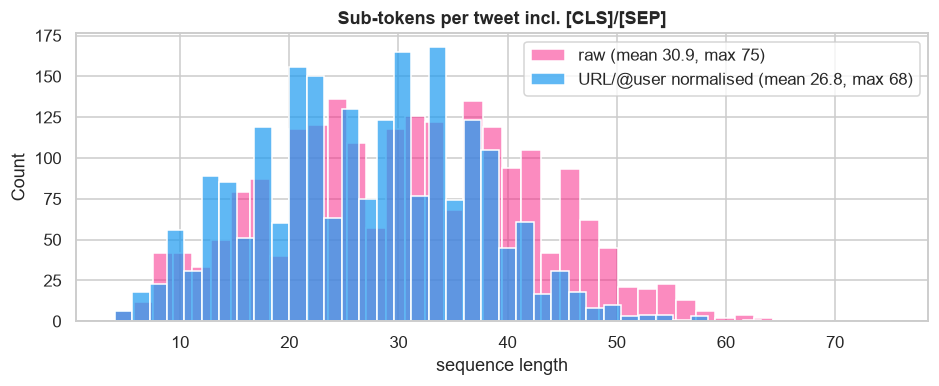

words per tweet 19.4 -> sub-tokens 30.9 (x1.59); words containing [UNK]: 0.00%


In [5]:
def kind(w):
    if re.match(r"https?://|www\.", w, re.I): return "url"
    if w.startswith("@") and len(w) > 1: return "mention"
    return "other"

ent_by_kind = Counter((kind(w), t != "O") for s, ts in zip(train_sents, train_tags) for w, t in zip(s, ts))
print("Entity tokens that are URLs:", ent_by_kind[("url", True)], "| that are @mentions:", ent_by_kind[("mention", True)],
      "| URL tokens:", ent_by_kind[("url", False)] + ent_by_kind[("url", True)],
      "| mention tokens:", ent_by_kind[("mention", False)] + ent_by_kind[("mention", True)])

def bert_normalise(w):
    """Replace URLs and user mentions by short placeholders (each becomes ONE known word), keep everything else."""
    k = kind(w)
    return "url" if k == "url" else "@user" if k == "mention" else w

def n_subtokens(sents, fn=lambda w: w):
    return [len(tokenizer([fn(w) for w in s], is_split_into_words=True)["input_ids"]) for s in sents]

raw_len, norm_len = n_subtokens(X_tr), n_subtokens(X_tr, bert_normalise)
unk_raw = np.mean([tokenizer.unk_token_id in tokenizer([w])["input_ids"] for s in X_tr for w in s]) * 100
fig, ax = plt.subplots(figsize=(10, 3.4))
sns.histplot(raw_len, bins=40, color=PALETTE[2], alpha=.5, label=f"raw (mean {np.mean(raw_len):.1f}, max {max(raw_len)})", ax=ax)
sns.histplot(norm_len, bins=40, color=PALETTE[0], alpha=.7, label=f"URL/@user normalised (mean {np.mean(norm_len):.1f}, max {max(norm_len)})", ax=ax)
ax.set_title("Sub-tokens per tweet incl. [CLS]/[SEP]"); ax.set_xlabel("sequence length"); ax.legend(); plt.show()
print(f"words per tweet {np.mean([len(s) for s in X_tr]):.1f} -> sub-tokens {np.mean(raw_len):.1f} "
      f"(x{np.mean(raw_len)/np.mean([len(s) for s in X_tr]):.2f}); words containing [UNK]: {unk_raw:.2f}%")

**Decision.** No URL and only one of ~1,300 @mention tokens is part of an entity, so replacing their text with the placeholders `url` / `@user` (labels unchanged) loses no label
information, shortens sequences substantially (faster training, less truncation) and removes meaningless sub-word noise.
We keep emoji, hashtags and original word boundaries. `MAX_LEN = 128` covers every tweet, so **nothing is truncated**,
and batches are **dynamically padded** to the longest sequence in each batch.

In [6]:
MAX_LEN = 128

def encode_split(sents, tags=None):
    """Tokenize word-split tweets and align word labels to sub-tokens (first sub-token keeps the label, rest -100)."""
    feats = []
    for i, s in enumerate(sents):
        enc = tokenizer([bert_normalise(w) for w in s], is_split_into_words=True, truncation=True, max_length=MAX_LEN)
        f = {k: enc[k] for k in ["input_ids", "attention_mask", "token_type_ids"]}
        if tags is not None:
            lab, prev = [], None
            for w in enc.word_ids():
                lab.append(-100 if w is None or w == prev else label2id[tags[i][w]]); prev = w
            f["labels"] = lab
        f["word_ids"] = [-1 if w is None else w for w in enc.word_ids()]
        feats.append(f)
    return feats

F_tr, F_va, F_te = encode_split(X_tr, y_tr), encode_split(X_va, y_va), encode_split(X_te, y_te)

# Integrity checks: every word got exactly one labelled sub-token, labels match the gold sequence, no truncation
for F, Y in [(F_tr, y_tr), (F_va, y_va), (F_te, y_te)]:
    for f, ys in zip(F, Y):
        kept = [id2label[l] for l in f["labels"] if l != -100]
        assert kept == ys, "label alignment error"
print("Alignment verified for all", len(F_tr) + len(F_va) + len(F_te), "tweets; longest sequence:",
      max(len(f["input_ids"]) for f in F_tr + F_va + F_te), "sub-tokens (no truncation)")
f = F_tr[3]
show_wide(pd.DataFrame({"sub-token": tokenizer.convert_ids_to_tokens(f["input_ids"]),
                        "word_id": ["–" if w == -1 else w for w in f["word_ids"]],
                        "label": [id2label.get(l, "-100") for l in f["labels"]]}).T)

Alignment verified for all 6244 tweets; longest sequence: 68 sub-tokens (no truncation)


,0,1,2,3,4,5,6,7,8,9,10,11
sub-token,[CLS],@,user,can,i,get,a,twitter,software,to,sp,##ew
word_id,–,0,0,1,2,3,4,5,6,7,8,8
label,-100,O,-100,O,O,O,O,B-company,O,O,O,-100


,12,13,14,15,16,17,18,19,20,21,22,23
sub-token,random,bullshit,about,airports,/,coffee,/,conferences,?,cause,that,would
word_id,9,10,11,12,12,12,12,12,13,14,15,16
label,O,O,O,O,-100,-100,-100,-100,O,O,O,O


,24,25,26,27,28,29
sub-token,free,up,some,time,.,[SEP]
word_id,17,18,19,20,21,–
label,O,O,O,O,O,-100


In [7]:
def make_dataset(feats, batch, shuffle=False, with_labels=True):
    """tf.data pipeline with dynamic padding. For training, tweets of similar length are bucketed together
    (shuffled within and across buckets) so that very little compute is wasted on [PAD] tokens."""
    keys = ["input_ids", "attention_mask", "token_type_ids"] + (["labels"] if with_labels else [])
    def gen():
        for f in feats: yield {k: f[k] for k in keys}
    sig = {k: tf.TensorSpec([None], tf.int32) for k in keys}
    ds = tf.data.Dataset.from_generator(gen, output_signature=sig)
    pad = {k: tf.constant(-100 if k == "labels" else 0, tf.int32) for k in keys}
    if shuffle:
        ds = ds.shuffle(len(feats), seed=SEED, reshuffle_each_iteration=True)
        bounds = [16, 24, 32, 40, 48, 64]
        ds = ds.bucket_by_sequence_length(lambda x: tf.shape(x["input_ids"])[0], bounds, [batch] * (len(bounds) + 1),
                                          padding_values=pad)
        return ds.shuffle(64, seed=SEED).prefetch(tf.data.AUTOTUNE)
    return ds.padded_batch(batch, padding_values=pad).prefetch(tf.data.AUTOTUNE)

## 4. Prediction → word-level labels (joining sub-tokens)
The model outputs one prediction per **sub-token**. To recover one label per original **word** we keep the
prediction of the **first sub-token** of each word (the same position that carried the label during training) and
discard predictions on continuation pieces (`##...`) and special tokens. A light **BIO repair** step then fixes
rare invalid sequences (e.g. `O → I-company` becomes `B-company`).

In [8]:
def repair_bio(tags):
    out, prev = [], "O"
    for t in tags:
        if t.startswith("I-") and prev[2:] != t[2:]: t = "B-" + t[2:]
        out.append(t); prev = t
    return out

def predict_words(model, feats, batch=64):
    logits = []
    ds = make_dataset(feats, batch, with_labels=False)
    for b in ds:
        out = model(b, training=False).logits.numpy()
        logits.extend(list(out))
    preds = []
    for f, lg in zip(feats, logits):
        ids = lg[:len(f["input_ids"])].argmax(-1)
        word_tags, prev = [], -1
        for pos, w in enumerate(f["word_ids"]):
            if w != -1 and w != prev: word_tags.append(id2label[int(ids[pos])])
            prev = w
        preds.append(repair_bio(word_tags))
    return preds

## 5. Training
* **Loss**: token-level cross-entropy computed inside the HF model, ignoring `-100` positions.
* **Optimiser**: AdamW (decoupled weight decay 0.01) with linear warm-up (10% of steps) and linear decay — the standard
  BERT fine-tuning recipe. A plain Adam run is included for comparison.
* **Early stopping**: on validation entity-F1 with `restore_best_weights=True`.
* Experiments vary **learning rate, batch size, optimiser and number of epochs**. Training is on CPU here, so the grid
  is deliberately small but targeted.

In [9]:
def log(msg):
    """Print to the notebook and append to a progress file (useful for long CPU runs)."""
    print(msg)
    with open(f"{OUT_DIR}/bert_progress.log", "a") as f: f.write(time.strftime("%H:%M:%S ") + msg + "\n")

class EntityF1(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs["val_f1"] = f1_score(y_va, predict_words(self.model, F_va))
        log(f"   epoch {epoch+1}: loss={logs['loss']:.4f} val_loss={logs['val_loss']:.4f} val_F1={logs['val_f1']:.4f}")

class EarlyStoppingMonitor(tf.keras.callbacks.Callback):
    """Shadow early stopping: never stops training, but records when EarlyStopping(patience) *would* have stopped
    and keeps a copy of the best weights. One long run then answers 'what if we had / had not stopped early?'."""
    def __init__(self, patience=2):
        super().__init__(); self.patience = patience
        self.best, self.best_epoch, self.stop_epoch, self.best_weights = -1, 0, None, None
    def on_epoch_end(self, epoch, logs=None):
        if logs["val_f1"] > self.best:
            self.best, self.best_epoch, self.best_weights = logs["val_f1"], epoch + 1, self.model.get_weights()
        elif self.stop_epoch is None and epoch + 1 - self.best_epoch >= self.patience:
            self.stop_epoch = epoch + 1

def train_bert(name, lr=5e-5, batch=16, epochs=5, optimizer="adamw", patience=2, early_stopping=True):
    tf.keras.utils.set_random_seed(SEED)
    model = TFAutoModelForTokenClassification.from_pretrained(CHECKPOINT, config=config)
    steps = int(np.ceil(len(F_tr) / batch)) * epochs
    if optimizer == "adamw":
        opt, _ = create_optimizer(init_lr=lr, num_train_steps=steps, num_warmup_steps=int(0.1 * steps), weight_decay_rate=0.01)
    else:
        opt = tf.keras.optimizers.Adam(lr)
    model.compile(optimizer=opt)                              # no loss argument -> uses the model's internal masked loss
    monitor = EarlyStoppingMonitor(patience)
    cbs = [EntityF1(), tf.keras.callbacks.EarlyStopping(monitor="val_f1", mode="max", patience=patience,
                                                        restore_best_weights=True) if early_stopping else monitor]
    log(f"{name}: lr={lr}, batch={batch}, max_epochs={epochs}, optimizer={optimizer}, early_stopping={early_stopping}")
    t0 = time.time()
    hist = model.fit(make_dataset(F_tr, batch, shuffle=True), validation_data=make_dataset(F_va, 32),
                     epochs=epochs, callbacks=cbs, verbose=0)
    train_min = round((time.time() - t0) / 60, 1)

    def evaluate(tag):
        va_pred, te_pred = predict_words(model, F_va), predict_words(model, F_te)
        return {"experiment": tag, "lr": lr, "batch": batch, "optimizer": optimizer,
                "epochs_run": len(hist.history["loss"]), "best_epoch": int(np.argmax(hist.history["val_f1"])) + 1,
                "val_F1": f1_score(y_va, va_pred), "test_P": precision_score(y_te, te_pred),
                "test_R": recall_score(y_te, te_pred), "test_F1": f1_score(y_te, te_pred), "train_min": train_min}, te_pred

    extra = None
    if not early_stopping:                                   # last-epoch weights = "no early stopping"
        extra, _ = evaluate(f"{name} (all {epochs} epochs, no early stopping)")
        extra["epochs_run"] = epochs
        model.set_weights(monitor.best_weights)              # best-validation weights = "with early stopping"
    res, te_pred = evaluate(name)
    if not early_stopping:
        res["epochs_run"] = monitor.stop_epoch or epochs
        res["train_min"] = round(train_min * res["epochs_run"] / epochs, 1)
        log(f"   early stopping would have halted after epoch {res['epochs_run']} (best epoch {monitor.best_epoch})")
    log(f"   -> val F1={res['val_F1']:.4f} | test F1={res['test_F1']:.4f} | {train_min} min\n")
    return model, hist.history, res, te_pred, extra

Run **B1** trains for a fixed 6 epochs with a *shadow* early-stopping monitor, which lets us measure the effect of
early stopping from a single run (Section 5.1). Runs **B2–B4** use real early stopping (patience 2).

In [10]:
BERT_EXPERIMENTS = {
    "B1 AdamW lr=5e-5 bs=16": dict(lr=5e-5, batch=16, epochs=6, early_stopping=False),
    "B2 AdamW lr=3e-5 bs=16": dict(lr=3e-5, batch=16, epochs=5),
    "B3 AdamW lr=5e-5 bs=32": dict(lr=5e-5, batch=32, epochs=5),
    "B4 Adam (no decay/warm-up) lr=3e-5 bs=16": dict(lr=3e-5, batch=16, epochs=4, optimizer="adam"),
}
import gc
bert_results, bert_hist, best_val, best, no_es = [], {}, -1, None, None
for name, kw in list(BERT_EXPERIMENTS.items())[:2 if SMOKE else None]:
    model, h, r, p, extra = train_bert(name, **(dict(kw, epochs=3) if SMOKE else kw))
    bert_results.append(r); bert_hist[name] = h
    no_es = extra or no_es
    if r["val_F1"] > best_val:            # best-on-validation model goes straight to disk (8 GB RAM: one model in memory)
        best_val, best = r["val_F1"], (name, p)
        model.save_pretrained(MODEL_DIR); tokenizer.save_pretrained(MODEL_DIR)
    del model; tf.keras.backend.clear_session(); gc.collect()

bert_df = pd.DataFrame(bert_results).set_index("experiment")
bert_df.drop(columns=["lr", "batch", "optimizer"]).round(4)

B1 AdamW lr=5e-5 bs=16: lr=5e-05, batch=16, max_epochs=6, optimizer=adamw, early_stopping=False


   epoch 1: loss=0.6953 val_loss=0.2096 val_F1=0.0819


   epoch 2: loss=0.1812 val_loss=0.1509 val_F1=0.4679


   epoch 3: loss=0.1070 val_loss=0.1316 val_F1=0.5392


   epoch 4: loss=0.0680 val_loss=0.1289 val_F1=0.5657


...

   epoch 2: loss=0.1810 val_loss=0.1592 val_F1=0.4803


   epoch 3: loss=0.1131 val_loss=0.1411 val_F1=0.5223


   epoch 4: loss=0.0732 val_loss=0.1465 val_F1=0.5746


   -> val F1=0.5746 | test F1=0.3881 | 61.0 min



,epochs_run,best_epoch,val_F1,test_P,test_R,test_F1,train_min
experiment,,,,,,,
B1 AdamW lr=5e-5 bs=16,6,6,0.5836,0.4319,0.4420,0.4369,78.6
B2 AdamW lr=3e-5 bs=16,5,5,0.5099,0.3352,0.3737,0.3534,50.6
B3 AdamW lr=5e-5 bs=32,5,4,0.4037,0.2657,0.3141,0.2879,42.2
B4 Adam (no decay/warm-up) lr=3e-5 bs=16,4,4,0.5746,0.4404,0.3470,0.3881,61.0


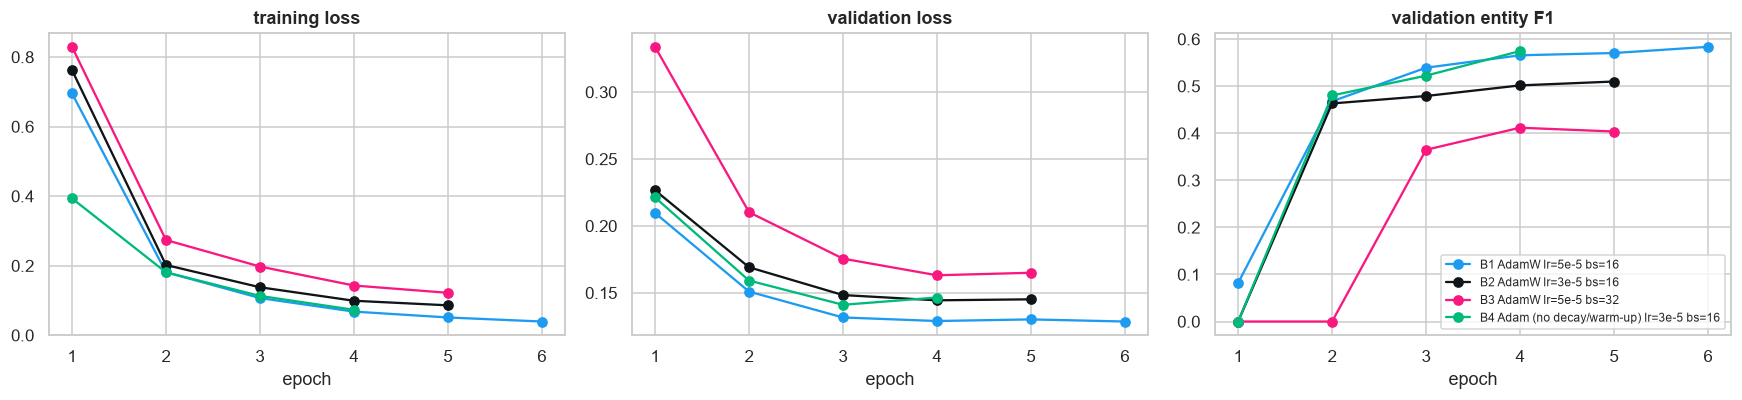

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for i, (name, h) in enumerate(bert_hist.items()):
    ep = np.arange(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["loss"], marker="o", color=PALETTE[i], label=name)
    axes[1].plot(ep, h["val_loss"], marker="o", color=PALETTE[i], label=name)
    axes[2].plot(ep, h["val_f1"], marker="o", color=PALETTE[i], label=name)
for ax, t in zip(axes, ["training loss", "validation loss", "validation entity F1"]):
    ax.set_title(t); ax.set_xlabel("epoch")
axes[2].legend(fontsize=8); plt.tight_layout(); plt.show()

### 5.1 Early stopping and the number of epochs
Run B1 trained for all 6 epochs while the shadow monitor recorded when early stopping (patience 2) would have halted
and kept the best-validation weights. We compare the **last-epoch** model (no early stopping) with the
**restored best** model (early stopping).

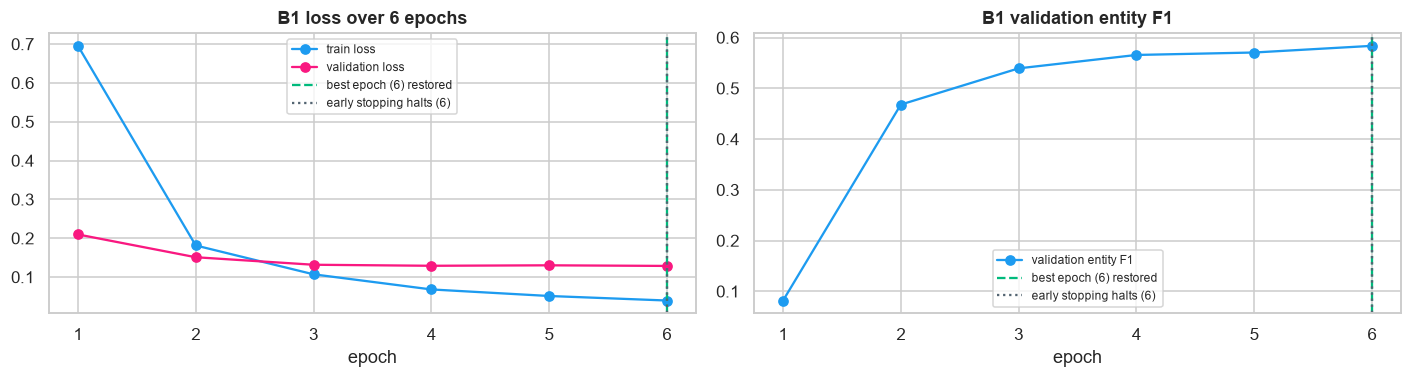

,epochs_run,best_epoch,val_F1,test_F1,train_min
"with early stopping (patience 2, best weights)",6,6,0.5836,0.4369,78.6
without early stopping (last epoch),6,6,0.5836,0.4369,78.6


In [12]:
BEST_NAME, best_pred = best
B1 = "B1 AdamW lr=5e-5 bs=16"
h1 = bert_hist[B1]; r1 = bert_df.loc[B1]
ep = np.arange(1, len(h1["loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(ep, h1["loss"], marker="o", color=PALETTE[0], label="train loss")
ax[0].plot(ep, h1["val_loss"], marker="o", color=PALETTE[2], label="validation loss")
ax[0].set_title("B1 loss over 6 epochs"); ax[0].set_xlabel("epoch")
ax[1].plot(ep, h1["val_f1"], marker="o", color=PALETTE[0], label="validation entity F1")
for a in ax:
    a.axvline(r1["best_epoch"], ls="--", color=PALETTE[3], label=f"best epoch ({int(r1['best_epoch'])}) restored")
    a.axvline(r1["epochs_run"], ls=":", color=PALETTE[7], label=f"early stopping halts ({int(r1['epochs_run'])})")
    a.legend(fontsize=8)
ax[1].set_title("B1 validation entity F1"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()
es_bert = pd.DataFrame([r1.rename("with early stopping (patience 2, best weights)"),
                        pd.Series(no_es, name="without early stopping (last epoch)")])
es_bert[["epochs_run", "best_epoch", "val_F1", "test_F1", "train_min"]].round(4)

## 6. Test-set evaluation of the selected BERT model

In [13]:
print("Selected on validation F1:", BEST_NAME)
assert all(len(p) == len(t) for p, t in zip(best_pred, y_te)), "word-level alignment failed"
print(f"Sub-tokens joined back to words: {sum(map(len, best_pred))} word labels for {len(best_pred)} tweets\n")
print(classification_report(y_te, best_pred, digits=3))

Selected on validation F1: B1 AdamW lr=5e-5 bs=16
Sub-tokens joined back to words: 61908 word labels for 3850 tweets



              precision    recall  f1-score   support

     company      0.562     0.523     0.542       621
    facility      0.186     0.261     0.217       253
     geo-loc      0.565     0.687     0.620       882
       movie      0.080     0.059     0.068        34
 musicartist      0.113     0.031     0.049       191
       other      0.192     0.202     0.197       584
      person      0.528     0.739     0.616       482
     product      0.105     0.041     0.059       246
  sportsteam      0.535     0.313     0.395       147
      tvshow      0.000     0.000     0.000        33

   micro avg      0.432     0.442     0.437      3473
   macro avg      0.287     0.286     0.276      3473
weighted avg      0.400     0.442     0.413      3473



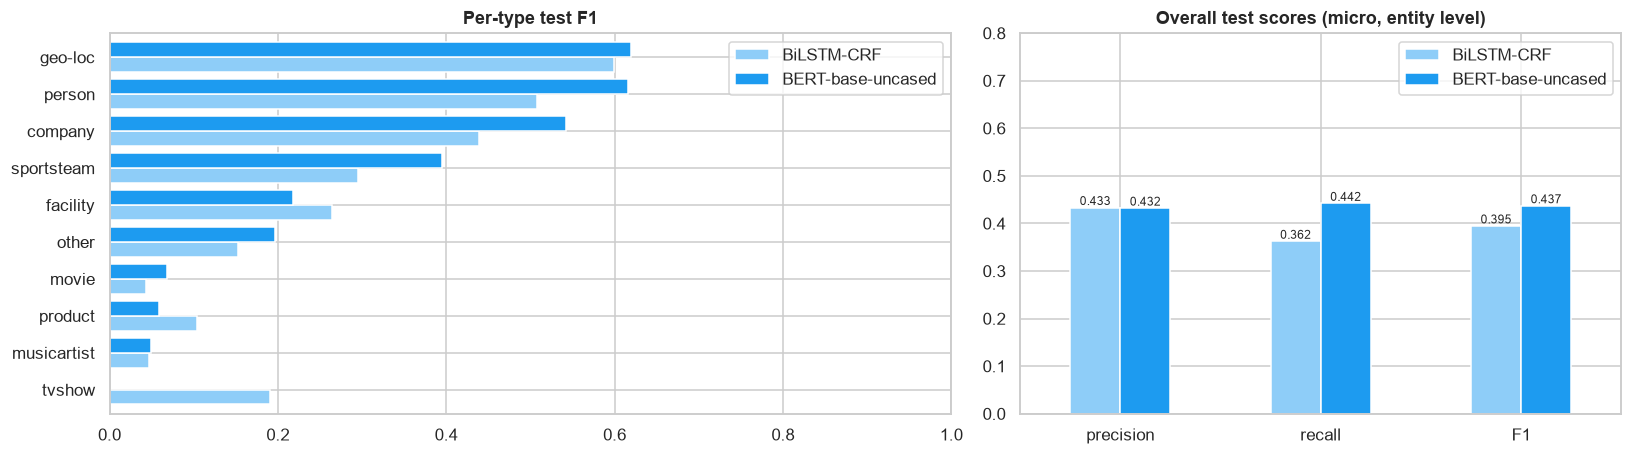

,BiLSTM-CRF,BERT-base-uncased
precision,0.4332,0.4319
recall,0.3622,0.4420
F1,0.3945,0.4369


In [14]:
lstm = json.load(open(f"{OUT_DIR}/lstm_best.json"))
rep = classification_report(y_te, best_pred, output_dict=True)
cmp = pd.DataFrame({"BiLSTM-CRF": pd.Series(lstm["per_type_f1"]),
                    "BERT-base-uncased": pd.Series({e: rep.get(e, {}).get("f1-score", 0.0) for e in ENTITY_TYPES})})
cmp["support"] = pd.Series({e: rep.get(e, {}).get("support", 0) for e in ENTITY_TYPES})
cmp = cmp.sort_values("BERT-base-uncased")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.4, 1]})
cmp[["BiLSTM-CRF", "BERT-base-uncased"]].plot.barh(ax=ax[0], color=[PALETTE[8], PALETTE[0]], width=.8)
ax[0].set_title("Per-type test F1"); ax[0].set_xlim(0, 1)
overall = pd.DataFrame({"BiLSTM-CRF": [lstm["test_P"], lstm["test_R"], lstm["test_F1"]],
                        "BERT-base-uncased": [precision_score(y_te, best_pred), recall_score(y_te, best_pred), f1_score(y_te, best_pred)]},
                       index=["precision", "recall", "F1"])
overall.plot.bar(ax=ax[1], color=[PALETTE[8], PALETTE[0]], rot=0)
for c in ax[1].containers: ax[1].bar_label(c, fmt="%.3f", fontsize=8)
ax[1].set_title("Overall test scores (micro, entity level)"); ax[1].set_ylim(0, 0.8)
plt.tight_layout(); plt.show()
overall.round(4)

## 7. Saving with `save_pretrained` and reloading
During the experiment loop the best-on-validation model was written with `model.save_pretrained(MODEL_DIR)` (weights +
`config.json` containing our `id2label`) and `tokenizer.save_pretrained(MODEL_DIR)`. We reload it from disk exactly as
a production service would, and verify it reproduces the in-training predictions.

In [15]:
print("Saved files:", sorted(os.listdir(MODEL_DIR)))
reloaded = TFAutoModelForTokenClassification.from_pretrained(MODEL_DIR)
re_pred = predict_words(reloaded, F_te[:200])
print("Reloaded model reproduces predictions on 200 test tweets:", re_pred == best_pred[:200])
print("id2label stored in config:", list(reloaded.config.id2label.items())[:4], "...")

Saved files: ['config.json', 'special_tokens_map.json', 'tf_model.h5', 'tokenizer.json', 'tokenizer_config.json', 'vocab.txt']


Reloaded model reproduces predictions on 200 test tweets: True
id2label stored in config: [(0, 'O'), (1, 'B-company'), (2, 'I-company'), (3, 'B-facility')] ...


## 8. Predictions on our own sentences
`ner()` takes raw text, splits it into words, runs BERT, **joins sub-tokens back into words** and finally groups
BIO tags into entity spans.

In [16]:
def ner(text, model=reloaded):
    words = text.split()
    feats = encode_split([words])
    tags = predict_words(model, feats)[0]
    ents, cur, typ = [], [], None
    for w, t in zip(words + [""], tags + ["O"]):
        if t.startswith("B-") or t == "O" or t[2:] != typ:
            if cur: ents.append((" ".join(cur), typ))
            cur, typ = ([w], t[2:]) if t != "O" else ([], None)
        else:
            cur.append(w)
    return words, tags, ents

# Show the sub-token view once, to illustrate the joining step
enc = tokenizer("Watching Stranger Things on Netflix".split(), is_split_into_words=True)
print("sub-tokens:", tokenizer.convert_ids_to_tokens(enc["input_ids"]))
print("word ids  :", enc.word_ids(), "\n")

MY_SENTENCES = [
    "Just landed in New York for the Apple keynote with Tim Cook tomorrow !",
    "Watching Game of Thrones tonight then Manchester United vs Chelsea on Sunday",
    "Taylor Swift new album is fire , listening on Spotify at Starbucks",
    "Microsoft and Google announce new AI partnership in London",
    "heading to the eiffel tower with @john after visiting paris museum",
    "Can't wait for the Lakers game at Staples Center , then Avengers Endgame with friends",
]
rows = []
for s in MY_SENTENCES:
    words, tags, ents = ner(s)
    print(" ".join(f"[{w}]{t}" if t != "O" else w for w, t in zip(words, tags)))
    print("   ->", ents, "\n")

sub-tokens: ['[CLS]', 'watching', 'stranger', 'things', 'on', 'netflix', '[SEP]']
word ids  : [None, 0, 1, 2, 3, 4, None] 



Just landed in [New]B-geo-loc [York]B-geo-loc for the [Apple]B-product keynote with [Tim]B-person [Cook]I-person tomorrow !
   -> [('New', 'geo-loc'), ('York', 'geo-loc'), ('Apple', 'product'), ('Tim Cook', 'person')] 



Watching [Game]B-other [of]I-other [Thrones]I-other tonight then [Manchester]B-sportsteam [United]I-sportsteam vs [Chelsea]B-sportsteam on Sunday
   -> [('Game of Thrones', 'other'), ('Manchester United', 'sportsteam'), ('Chelsea', 'sportsteam')] 



[Taylor]B-person [Swift]I-person new album is fire , listening on Spotify at [Starbucks]B-company
   -> [('Taylor Swift', 'person'), ('Starbucks', 'company')] 



[Microsoft]B-company and [Google]B-company announce new AI partnership in [London]B-geo-loc
   -> [('Microsoft', 'company'), ('Google', 'company'), ('London', 'geo-loc')] 



heading to the [eiffel]B-facility [tower]I-facility with @john after visiting [paris]B-geo-loc [museum]B-facility
   -> [('eiffel tower', 'facility'), ('paris', 'geo-loc'), ('museum', 'facility')] 



Can't wait for the [Lakers]B-sportsteam game at [Staples]B-facility [Center]I-facility , then [Avengers]B-other Endgame with friends
   -> [('Lakers', 'sportsteam'), ('Staples Center', 'facility'), ('Avengers', 'other')] 



## 9. Error analysis on the test set

In [17]:
def spans(tokens, tags):
    out, cur, typ, start = set(), [], None, 0
    for i, t in enumerate(tags + ["O"]):
        if t.startswith("B-") or t == "O" or t[2:] != typ:
            if cur: out.add((start, i, typ))
            cur, typ, start = ([i], t[2:], i) if t != "O" else ([], None, i)
        else: cur.append(i)
    return out

err = Counter()
for s, g, p in zip(X_te, y_te, best_pred):
    G, P = spans(s, g), spans(s, p)
    for (a, b, t) in G - P:
        overl = [q for q in P if q[0] < b and a < q[1]]
        if not overl: err["missed entirely (false negative)"] += 1
        elif any(q[2] == t for q in overl): err["right type, wrong boundary"] += 1
        else: err["right span/overlap, wrong type"] += 1
    for (a, b, t) in P - G:
        if not [q for q in G if q[0] < b and a < q[1]]: err["spurious entity (false positive)"] += 1
err_df = pd.Series(err).sort_values(ascending=False).to_frame("count")
err_df["share %"] = (100 * err_df["count"] / err_df["count"].sum()).round(1)
err_df

,count,share %
missed entirely (false negative),860,34.3
"right span/overlap, wrong type",672,26.8
spurious entity (false positive),570,22.7
"right type, wrong boundary",406,16.2


In [18]:
json.dump({"experiments": bert_df.reset_index().to_dict(orient="records"), "selected": BEST_NAME,
           "test_P": precision_score(y_te, best_pred), "test_R": recall_score(y_te, best_pred),
           "test_F1": f1_score(y_te, best_pred), "per_type_f1": cmp["BERT-base-uncased"].round(4).to_dict(),
           "early_stopping": es_bert[["epochs_run", "best_epoch", "val_F1", "test_F1"]].to_dict(),
           "errors": err_df["count"].to_dict()},
          open(f"{OUT_DIR}/bert_results.json", "w"), indent=2, default=float)

## Summary of Part B
* Fine-tuned BERT (B1) is the best model overall: test F1 0.437 against 0.395 for the selected BiLSTM-CRF, with
  precision and recall both improving. The gains are largest on frequent types with strong context cues, such as
  `person`, `company` and `sportsteam` (about +10 F1 points each). Rare types (`tvshow`, `movie`, `product`,
  `musicartist`) stay near zero for both models: a few dozen training examples are not enough, even for BERT.
* **The optimiser recipe matters.** AdamW with warm-up and linear decay at lr 5e-5 and batch 16 clearly beat a lower
  learning rate, a larger batch and plain Adam. Plain Adam reached a similar validation F1 but generalised worse on
  the test set (0.388).
* **The tokenization step is the crux.** WordPiece removes the OOV problem, but labels must be re-aligned to the
  first sub-token and predictions joined back to words. Both steps are verified with assertions.
* **Early stopping.** With the linear learning-rate decay, validation F1 kept improving through all 6 epochs of B1,
  so early stopping never triggered. Validation loss flattened after epoch 4 while training loss kept falling, a
  sign that more epochs would start to over-fit. For the runs with real early stopping (B2–B4), it acted as a
  safety net that would have stopped a run once validation F1 stalled.
* **Errors.** The largest error category is entities missed entirely (about a third), followed by correct spans
  with the wrong type, which is typical for WNUT-16, where most test entities are novel and the uncased model loses
  capitalisation cues.